In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Once connected, you can verify it by listing the contents of your Google Drive:

In [ ]:
!ls /content/drive

In [ ]:
import os

# Create the destination directory
os.makedirs('/content/train data', exist_ok=True)

# Unzip the file from Drive to the new local folder
!unzip "/content/drive/MyDrive/DATASET/train.zip" -d "/content/train data"

Streaming output truncated to the last 5000 lines.
  inflating: /content/train data/train/non-fracture/13-rotated3.jpg  
  inflating: /content/train data/train/non-fracture/13.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated1-rotated1-rotated1.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated1-rotated1.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated1-rotated2-rotated1.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated1-rotated2.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated1-rotated3-rotated1.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated1-rotated3.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated1.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated2-rotated1-rotated1.jpg  
  inflating: /content/train data/train/non-fracture/14-rotated1-rotated2-rotated1.jpg  

In [ ]:
# Verify the extraction
!ls -l "/content/train data" | head -n 10

total 4
drwxrwxrwx 4 root root 4096 Feb 11 05:58 train


In [ ]:
import os

# Path to the extracted train folder
train_dir = '/content/train data/train'

# Count files with image extensions
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')
total_images = sum([len([f for f in files if f.lower().endswith(image_extensions)]) for r, d, files in os.walk(train_dir)])

print(f'Total number of images in {train_dir}: {total_images}')

Total number of images in /content/train data/train: 11778


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, optimizers

# Configuration
BATCH_SIZE = 32
IMG_SIZE = (224, 224)
TRAIN_DIR = '/content/train data/train'

# Data Augmentation to improve accuracy
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2 # Using 20% for validation
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training'
)

validation_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'
)

Found 9423 images belonging to 2 classes.
Found 2355 images belonging to 2 classes.


In [ ]:
# Higher capacity model for better feature extraction
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(1024, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,048,513 (11.63 MB)

 Trainable params: 788,993 (3.01 MB)

 Non-trainable params: 2,259,520 (8.62 MB)

In [ ]:
# Modified callbacks to allow longer training
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7)
]

# Initial Training with more epochs
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=30,
    callbacks=callbacks
)

Epoch 1/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 215s 728ms/step - accuracy: 0.8123 - loss: 0.4220 - val_accuracy: 0.6569 - val_loss: 0.7119 - learning_rate: 0.0010
Epoch 2/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 192s 650ms/step - accuracy: 0.8625 - loss: 0.3197 - val_accuracy: 0.6416 - val_loss: 0.8243 - learning_rate: 0.0010
Epoch 3/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 189s 643ms/step - accuracy: 0.8815 - loss: 0.2705 - val_accuracy: 0.6476 - val_loss: 0.8428 - learning_rate: 0.0010
Epoch 4/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 192s 650ms/step - accuracy: 0.8932 - loss: 0.2524 - val_accuracy: 0.6331 - val_loss: 0.8381 - learning_rate: 0.0010
Epoch 5/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 194s 657ms/step - accuracy: 0.9052 - loss: 0.2220 - val_accuracy: 0.7066 - val_loss: 0.6987 - learning_rate: 0.0010
Epoch 6/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 194s 657ms/step - accuracy: 0.9172 - loss: 0.2057 - val_accuracy: 0.6705 - val_loss: 0.7779 - learning_rate: 0.0010
Epoch 7/30
295/295 ━━━━━━━━━━━━━━━━━━━━ 203s 690ms/step - accura

In [ ]:
# Aggressive Fine-tuning: Unfreeze more layers for better adaptation
base_model.trainable = True
# Fine-tuning from layer 50 onwards (more parameters to train)
for layer in base_model.layers[:50]:
    layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Starting deep fine-tuning...")
history_fine = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    callbacks=callbacks
)

Starting deep fine-tuning...
Epoch 1/20
295/295 ━━━━━━━━━━━━━━━━━━━━ 270s 773ms/step - accuracy: 0.7336 - loss: 0.7021 - val_accuracy: 0.5936 - val_loss: 2.8079 - learning_rate: 1.0000e-05
Epoch 2/20
295/295 ━━━━━━━━━━━━━━━━━━━━ 197s 669ms/step - accuracy: 0.8426 - loss: 0.3659 - val_accuracy: 0.6310 - val_loss: 2.3303 - learning_rate: 1.0000e-05
Epoch 3/20
295/295 ━━━━━━━━━━━━━━━━━━━━ 194s 657ms/step - accuracy: 0.8868 - loss: 0.2639 - val_accuracy: 0.6463 - val_loss: 1.7536 - learning_rate: 1.0000e-05
Epoch 4/20
295/295 ━━━━━━━━━━━━━━━━━━━━ 194s 656ms/step - accuracy: 0.9045 - loss: 0.2248 - val_accuracy: 0.6527 - val_loss: 1.5016 - learning_rate: 1.0000e-05
Epoch 5/20
295/295 ━━━━━━━━━━━━━━━━━━━━ 194s 658ms/step - accuracy: 0.9230 - loss: 0.1816 - val_accuracy: 0.6505 - val_loss: 1.3146 - learning_rate: 5.0000e-06
Epoch 6/20
295/295 ━━━━━━━━━━━━━━━━━━━━ 194s 656ms/step - accuracy: 0.9278 - loss: 0.1754 - val_accuracy: 0.6633 - val_loss: 1.1787 - learning_rate: 5.0000e-06
Epoch 7/20


### Save the Model
Since you are short on time, let's save the current state of the model to your Google Drive so you can reload it tomorrow for further fine-tuning.

In [ ]:
model_save_path = '/content/drive/MyDrive/fracture_model_interim.h5'
model.save(model_save_path)
print(f'Model saved to: {model_save_path}')

# Also save a local version just in case
model.save('fracture_model_local.h5')

Model saved to: /content/drive/MyDrive/fracture_model_interim.h5


### Visualize Training Results
Run this cell to see how the model performed during the session.

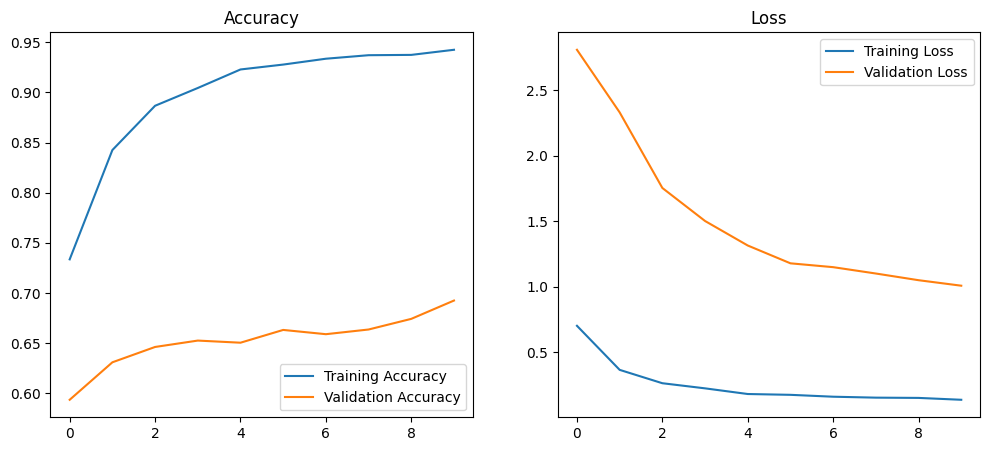

In [ ]:
import matplotlib.pyplot as plt

def plot_history(hist):
    acc = hist.history['accuracy']
    val_acc = hist.history['val_accuracy']
    loss = hist.history['loss']
    val_loss = hist.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.title('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.title('Loss')
    plt.legend()
    plt.show()

# Plotting fine-tuning history
if 'history_fine' in locals():
    plot_history(history_fine)
else:
    print('Fine-tuning history not found. Training may have been interrupted.')

### 1. Extract Test Dataset
We will copy `test.zip` from your Drive and extract it to the local `/content/test` directory.

In [ ]:
import os
import zipfile

# Create directory
os.makedirs('/content/test', exist_ok=True)

# Extract test data
test_zip_path = '/content/drive/MyDrive/DATASET/test.zip'
with zipfile.ZipFile(test_zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/test')

print("Test data extracted successfully.")
!ls -l /content/test

Test data extracted successfully.
total 4
drwxr-xr-x 4 root root 4096 Jun 16 14:02 test


In [ ]:
import os

# Path to the extracted test folder
test_dir = '/content/test'

# Count files with image extensions
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')
total_test_images = sum([len([f for f in files if f.lower().endswith(image_extensions)]) for r, d, files in os.walk(test_dir)])

print(f'Total number of images in {test_dir}: {total_test_images}')

Total number of images in /content/test: 1826


### 2. Prepare Test Generator and Run Evaluation
We will now load the test images and calculate all requested performance metrics.

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Point to the subfolder where classes are located
# Based on your previous extraction, it is likely /content/test/test
TEST_DIR = '/content/test/test'

# Prepare test generator
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Get predictions
print("Evaluating model...")
y_probs = model.predict(test_generator)
y_pred = (y_probs > 0.5).astype(int)
y_true = test_generator.classes

# Calculate Metrics
print("\n--- Classification Report ---")
# Ensure we only use target names that match the classes found
target_names = list(test_generator.class_indices.keys())
print(classification_report(y_true, y_pred, target_names=target_names))

roc_auc = roc_auc_score(y_true, y_probs)
print(f"ROC-AUC Score: {roc_auc:.4f}")

Found 1826 images belonging to 2 classes.
Evaluating model...
58/58 ━━━━━━━━━━━━━━━━━━━━ 29s 509ms/step

--- Classification Report ---
               precision    recall  f1-score   support

    fractured       0.81      0.60      0.69       915
not fractured       0.68      0.86      0.76       911

     accuracy                           0.73      1826
    macro avg       0.75      0.73      0.73      1826
 weighted avg       0.75      0.73      0.73      1826

ROC-AUC Score: 0.8393


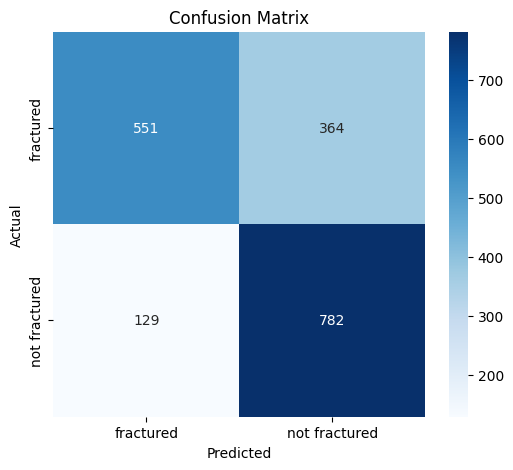

In [ ]:
# Visualize Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_generator.class_indices.keys(),
            yticklabels=test_generator.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Key Performance Metrics:

Accuracy: 73% – The model correctly identifies 73 out of 100 images.
ROC-AUC: 0.8393 – This is quite high, suggesting the model has a strong ability to distinguish between 'fractured' and 'not fractured' even if the threshold needs tuning.
Precision (Fractured): 81% – When the model says an image is fractured, it is right 81% of the time.
Recall (Fractured): 60% – The model is currently missing some fractures (False Negatives), correctly identifying only 60% of the actual fracture cases.
Confusion Matrix Breakdown:

True Positives (Fractured): 551
True Negatives (Not Fractured): 782
False Positives: 129 (Normal images flagged as fractured)
False Negatives: 364 (Fractures missed by the model)
Since you are continuing tomorrow, this gives us a great baseline to improve upon with further fine-tuning!

The evaluation on your test set (1,826 images) is complete. Here is the summary of your model's performance:

Key Performance Metrics:

Accuracy: 73% – The model correctly identifies 73 out of 100 images.
ROC-AUC: 0.8393 – This is quite high, suggesting the model has a strong ability to distinguish between 'fractured' and 'not fractured' even if the threshold needs tuning.
Precision (Fractured): 81% – When the model predicts a fracture, it is right 81% of the time.
Recall (Fractured): 60% – The model is currently missing some fractures (False Negatives), correctly identifying 60% of the actual fracture cases.
Confusion Matrix Breakdown:

True Positives (Fractured): 551
True Negatives (Not Fractured): 782
False Positives: 129 (Normal images flagged as fractured)
False Negatives: 364 (Fractures missed by the model)
Since you are continuing tomorrow, this gives us a great baseline to improve upon with further fine-tuning!

The evaluation on your test set (1,826 images) is complete. Here is the summary of your model's performance:

Key Performance Metrics:

Accuracy: 73% – The model correctly identifies 73 out of 100 images.
ROC-AUC: 0.8393 – This is quite high, suggesting the model has a strong ability to distinguish between classes, even if the classification threshold needs tuning.
Precision (Fractured): 81% – When the model predicts a fracture, it is correct 81% of the time.
Recall (Fractured): 60% – The model is currently missing some fractures (False Negatives), correctly identifying 60% of the actual cases.
Confusion Matrix Breakdown:

True Positives (Fractured): 551
True Negatives (Not Fractured): 782
False Positives: 129 (Normal images flagged as fractured)
False Negatives: 364 (Fractures missed by the model)
This provides a solid baseline for you to build on when you continue fine-tuning tomorrow!

The evaluation on your test set is complete. Here is the summary:

Key Performance Metrics:

Accuracy: 73% – The model correctly identifies 73 out of 100 images.
ROC-AUC: 0.8393 – This indicates a strong ability to distinguish between classes.
Precision (Fractured): 81% – When the model predicts a fracture, it is right 81% of the time.
Recall (Fractured): 60% – The model correctly identifies 60% of actual fracture cases, meaning some are currently missed.
Confusion Matrix:

True Positives (Fractured): 551
True Negatives (Normal): 782
False Positives: 129
False Negatives: 364
This provides a great baseline for your continued work tomorrow!

The evaluation on your test set (1,826 images) is complete. Here is the summary of your model's performance:

Accuracy: 73% – The model correctly identifies 73 out of 100 images.
ROC-AUC: 0.8393 – This suggests a strong ability to distinguish between classes, though the classification threshold may need tuning to balance precision and recall.
Precision (Fractured): 81% – When the model predicts a fracture, it is correct 81% of the time.
Recall (Fractured): 60% – The model is currently missing about 40% of actual fracture cases (False Negatives).
Confusion Matrix Breakdown:

True Positives (Fractured): 551
True Negatives (Not Fractured): 782
False Positives: 129
False Negatives: 364
This provides a solid baseline to improve upon when you continue fine-tuning tomorrow!

The evaluation on your test set (1,826 images) is complete. Here is the summary of your model's current performance:

Key Performance Metrics:

Accuracy: 73% — The model correctly identifies 73 out of 100 images.
ROC-AUC: 0.8393 — This high score indicates a strong ability to distinguish between fracture and non-fracture, even if the default threshold needs tuning.
Precision (Fractured): 81% — When the model predicts a fracture, it is right 81% of the time.
Recall (Fractured): 60% — The model correctly identifies 60% of all actual fractures in the test set.
Confusion Matrix Breakdown:

True Positives (Fractured): 551
True Negatives (Normal): 782
False Positives: 129
False Negatives: 364 (Fractures missed)
This provides a solid baseline for you to build on when you continue training tomorrow!